# Notebook_B (Sinh viên B): chia dữ liệu, năm mô hình, tinh chỉnh, RQ3, SHAP, chẩn đoán

**Đề tài**: Quỹ đạo xe không người lái 3 và 8 giây có bất định (Waymo Open Motion)

**Khung SDG**: SDG 11 và 9: an toàn xe tự hành.

**Vai trò**: Sinh viên B nhận `data/processed/feat_core_origin10.parquet` (mỗi xe một dòng tại step 10), `feat.parquet` và `manifest.json` từ Notebook_A, làm Bước 4 và Bước 6, vẽ hình so sánh mô hình, giải thích chỉ số, tinh chỉnh, câu hỏi thứ ba, SHAP và chẩn đoán vì sao tốt hay chưa tốt. Mọi bảng lưu `report/table_*.csv`, mọi hình `report/fig_rq2_*.png`, `fig_rq3_*.png`.

**Quy tắc**: không chạm tập kiểm thử khi tinh chỉnh; mỗi kết luận phải kèm số; báo cáo slot 3 thứ Tư và thứ Bảy (12:30 đến 14:45).

**Theo file góp ý và file hướng dẫn trực quan hoá:** 3 s và 8 s dùng chung một bảng và một lần chia; chọn mô hình chỉ trên train; có khoảng tin cậy, mốc vật lý mạnh hơn, tách xe đứng yên / đang chạy; bỏ Chronos; hình vẽ đúng bề rộng in, chữ 8 pt, một màu nhấn, không tiêu đề trong hình.

## Vừa làm vừa hỏi AI và ghi Audit Log: cách làm nhẹ nhàng, không rối

**Tinh thần**: AI là bạn cùng làm, không phải người làm thay. Bạn được hỏi AI bất cứ lúc nào; điều duy nhất phải giữ là *kiểm tra một lần* trước khi dùng và *ghi lại 2 phút* nếu câu hỏi đó thay đổi việc bạn làm.

**Khi nào hỏi AI** (theo thứ tự):
1. Đọc ô hướng dẫn của bước đang làm (1 phút).
2. Thử tự làm 15 phút.
3. Bí quá 15 phút thì hỏi AI với mẫu: *"Tôi đang làm Bước X của dự án Y. Dữ liệu có cột A, B, C. Tôi muốn Z. Đây là code và lỗi: ... Hãy giải thích nguyên nhân và sửa, giữ nguyên tên biến."*
4. Chạy thử code AI đưa trên dữ liệu thật; so một con số bằng tay hoặc bằng cách thứ hai.
5. Nếu vẫn bí sau 30 phút, ghi lại lỗi và hỏi giảng viên ở kênh nhóm.

**Ghi Audit Log thế nào cho không áp lực**: chỉ ghi các prompt *đã thay đổi việc bạn làm* (thường 3 đến 5 prompt một tuần, 15 đến 20 cả kỳ). Mỗi dòng 5 ô, điền trong 2 phút ngay khi dùng, không để cuối tuần:

| Ngày, bước | Prompt (rút gọn) | AI trả lời gì (1 dòng) | Tôi kiểm tra hoặc sửa gì | Dùng vào đâu |
|---|---|---|---|---|
| 09/09, Bước 3 | viết truy vấn trung bình trượt 7 ngày theo trạm | đưa AVG OVER ROWS 6 PRECEDING | thiếu PARTITION BY site_num, thêm và thử 2 trạm | Q3 trong sql/queries.sql |

Cột thứ tư chính là *Human Delta* và là thứ hội đồng hỏi; ghi thật, kể cả khi AI đúng ("kiểm tra bằng 10 dòng tính tay, khớp"). Ba lần bạn phát hiện AI sai trong cả kỳ là đủ yêu cầu.

**Nhịp làm việc**: mỗi ngày 1,5 đến 2 giờ vào đúng bước của tuần, xong một ô thì commit; thứ Ba và thứ Sáu slot 1 báo cáo năm mục đúng tiến độ, dù kết quả chưa đẹp. Siêng và đúng nhịp quan trọng hơn giỏi: nhóm báo cáo đều 6 lần trong 3 tuần luôn có bài, nhóm im lặng đến tuần 3 thường không kịp.

## Bước 0: kiểm tra bàn giao từ Notebook_A

Đọc `manifest.json`, so mã băm và số dòng với file parquet; nếu lệch thì báo Sinh viên A chạy lại Notebook_A trước khi tiếp tục. Notebook_B đọc bảng chính từ khoá `model_table` của manifest và kiểm mã MD5 `origin_md5`.

In [1]:
# Setup: libraries, paper figure style (same as Notebook A), constants and shared helpers
import os, json, hashlib, time, pickle, warnings, platform
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from PIL import Image
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold, RandomizedSearchCV, cross_val_predict
from sklearn.metrics import make_scorer, mean_absolute_error as MAE, mean_squared_error as MSE
from sklearn.metrics import roc_auc_score, average_precision_score, precision_score, recall_score, f1_score
from lightgbm import LGBMRegressor, LGBMClassifier
from xgboost import XGBRegressor
warnings.filterwarnings("ignore")
np.random.seed(42)
os.makedirs("report", exist_ok=True)
FIG_W = 4.8  # LNCS text width in inches: figures are drawn at print size, so 8 pt stays 8 pt
C_TEXT, C_BASE, C_MID, C_ACCENT, C_GREY = "#1F3B57", "#9CC9E8", "#4F8FC0", "#FF7F66", "#AEB9C4"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 8, "axes.labelsize": 8, "xtick.labelsize": 8,
    "ytick.labelsize": 8, "legend.fontsize": 8, "text.color": C_TEXT, "axes.labelcolor": C_TEXT,
    "axes.edgecolor": C_TEXT, "xtick.color": C_TEXT, "ytick.color": C_TEXT, "axes.linewidth": 0.6,
    "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white", "axes.grid": False,
    "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 300, "pdf.fonttype": 42})
SPLIT_SEED, TEST_FRAC, CAL_FRAC = 42, 0.30, 0.25
MODEL_SEEDS = [0, 1, 2, 3, 4]   # docx 5.7: these seeds change ONLY the model's random_state; the split is fixed
N_ITER, N_BOOT, ALPHA, STOP_SPEED = 20, 2000, 0.10, 0.5
HORIZONS = {"3s": 3.0, "8s": 8.0}
TARGET = {"3s": "y_disp_3s", "8s": "y_disp_8s"}
NICE = {"speed": "Current speed", "acc": "Acceleration", "yaw_rate": "Yaw rate",
        "dspeed_10step": "Speed change over 1 s", "acc_ma1s": "Mean acceleration over 1 s",
        "yaw_ma1s": "Mean yaw rate over 1 s", "length": "Vehicle length", "n_agents": "Agents in scene"}
MODEL_NAMES = ["Ridge", "Random Forest", "HistGradientBoosting", "LightGBM", "XGBoost"]
BASELINES = ["Constant velocity", "Constant acceleration", "CTRV"]
GRIDS = {
    "Ridge": {"ridge__alpha": [0.01, 0.1, 1.0, 10.0, 100.0]},
    "Random Forest": {"n_estimators": [200, 300, 500], "max_depth": [None, 6, 10, 16], "min_samples_leaf": [1, 3, 5, 10],
                      "max_features": [0.5, 0.7, 1.0]},
    "HistGradientBoosting": {"learning_rate": [0.03, 0.05, 0.1], "max_iter": [100, 200, 400], "max_leaf_nodes": [7, 15, 31],
                             "min_samples_leaf": [10, 20, 40], "l2_regularization": [0.0, 0.1, 1.0]},
    "LightGBM": {"n_estimators": [100, 300, 600], "learning_rate": [0.02, 0.05, 0.1], "num_leaves": [7, 15, 31],
                 "min_child_samples": [10, 20, 40], "subsample": [0.8, 1.0], "subsample_freq": [1], "colsample_bytree": [0.8, 1.0]},
    "XGBoost": {"n_estimators": [100, 300, 600], "learning_rate": [0.02, 0.05, 0.1], "max_depth": [3, 4, 6],
                "subsample": [0.8, 1.0], "colsample_bytree": [0.8, 1.0], "min_child_weight": [1, 5, 10]},
}
def make_model(name, seed=0, params=None):
    p = dict(params or {})
    if name == "Ridge":
        return make_pipeline(StandardScaler(), Ridge(**{k.replace("ridge__", ""): v for k, v in p.items()}))
    if name == "Random Forest":
        return RandomForestRegressor(random_state=seed, n_jobs=-1, **p)
    if name == "HistGradientBoosting":
        return HistGradientBoostingRegressor(random_state=seed, **p)
    if name == "LightGBM":
        return LGBMRegressor(random_state=seed, verbose=-1, **p)
    if name == "XGBoost":
        return XGBRegressor(random_state=seed, n_jobs=-1, verbosity=0, **p)
    raise ValueError(name)
def clip0(p):
    return np.clip(np.asarray(p, float), 0, None)  # displacement cannot be negative
mae_scorer = make_scorer(lambda y, p: MAE(y, clip0(p)), greater_is_better=False)
def scenario_split(df, seed=SPLIT_SEED, frac=TEST_FRAC):
    sc = np.sort(df["scenario"].unique())
    te_sc = np.random.RandomState(seed).choice(sc, int(np.ceil(len(sc) * frac)), replace=False)
    m = df["scenario"].isin(te_sc)
    return df[~m].copy(), df[m].copy()
def boot_indices(scen, n=N_BOOT, seed=0):
    """Scenario-cluster bootstrap: each resample draws test scenarios with replacement and keeps all their rows."""
    codes, inv = np.unique(np.asarray(scen), return_inverse=True)
    rows_of = [np.where(inv == g)[0] for g in range(len(codes))]
    rng = np.random.default_rng(seed)
    return [np.concatenate([rows_of[g] for g in rng.integers(0, len(codes), len(codes))]) for _ in range(n)]
def boot_ci(idx_list, fn):
    return np.quantile(np.array([fn(i) for i in idx_list]), [0.025, 0.975])
def baseline_preds(df, h):
    """docx 3.4: physical baselines from the current state (1-s means of acceleration and yaw rate reduce noise)."""
    v, a, w = df["speed"].to_numpy(), df["acc_ma1s"].to_numpy(), df["yaw_ma1s"].to_numpy()
    t_stop = np.where(a < 0, v / np.maximum(-a, 1e-9), np.inf)          # vehicle stops before h when braking
    ca = np.where(t_stop < h, v ** 2 / (2 * np.maximum(-a, 1e-9)), v * h + 0.5 * a * h ** 2)
    ctrv = np.where(np.abs(w) > 1e-4, 2 * v / np.maximum(np.abs(w), 1e-4) * np.abs(np.sin(w * h / 2)), v * h)  # chord of the arc
    return {"Constant velocity": clip0(v * h), "Constant acceleration": clip0(ca), "CTRV": clip0(ctrv)}
def save_fig(fig, name):
    fig.savefig(f"report/{name}.png")
    fig.savefig(f"report/{name}.pdf")
    plt.show()
    plt.close(fig)
def save_text(name, text):
    open(f"report/{name}", "w", encoding="utf-8").write(text)
    print(text)
print("Python", platform.python_version(), "|", platform.processor() or platform.machine())
# Handoff check from Notebook A
man = json.load(open("data/processed/manifest.json"))
path = man["model_table"]
assert hashlib.md5(open(path, "rb").read()).hexdigest() == man["origin_md5"], "origin table differs from Notebook A handoff"
core = pd.read_parquet(path)
X_COLS = man["origin_feature_cols"]
assert len(X_COLS) == 8 and (core["step"] == man["origin_step"]).all() and not core.duplicated("unit").any()
assert core[X_COLS + ["y_disp_3s", "y_disp_8s"]].notna().all().all()
print(f"rows={len(core)} | vehicles={core['unit'].nunique()} | scenarios={core['scenario'].nunique()} | "
      f"stationary share={(core['motion_state'] == 'stationary').mean():.3f}")
print("features:", [NICE[c] for c in X_COLS])

Python 3.11.16 | x86_64
rows=1172 | vehicles=1172 | scenarios=1051 | stationary share=0.689
features: ['Current speed', 'Acceleration', 'Yaw rate', 'Speed change over 1 s', 'Mean acceleration over 1 s', 'Mean yaw rate over 1 s', 'Vehicle length', 'Agents in scene']


## Bước 4: chia dữ liệu và bảng đặc trưng

**Làm gì**: dùng bảng step 10 của Notebook A (8 biến chung cho cả 3 s và 8 s). Chia **một lần theo cảnh** (30% số cảnh làm test), dùng chung cho cả hai horizon (góp ý 1a). Bảng ghi số dòng, số xe và số cảnh của mỗi phần (góp ý 5.5).

**Vì sao chia theo cảnh**: các xe trong cùng cảnh có tương quan; cảnh trong test không được xuất hiện khi huấn luyện. Bước 7 đo xem chia ngẫu nhiên theo dòng làm kết quả đẹp giả đến mức nào.

**Mốc vật lý** (góp ý 3.4): giữ nguyên tốc độ, giữ nguyên gia tốc (có xử lý xe dừng hẳn) và CTRV.

In [2]:
# One scenario-disjoint split shared by both horizons
train, test = scenario_split(core)
assert set(train["scenario"]).isdisjoint(set(test["scenario"]))
Xtr, Xte = train[X_COLS], test[X_COLS]
split_tab = pd.DataFrame([{"part": n, "rows": len(d), "vehicles": d["unit"].nunique(), "scenarios": d["scenario"].nunique(),
                           "stationary_share": (d["motion_state"] == "stationary").mean()} for n, d in [("train", train), ("test", test)]])
split_tab.to_csv("report/table_split.csv", index=False)
display(split_tab.round(3))
BOOT_IDX = boot_indices(test["scenario"])  # reused for every confidence interval on the core test set

,part,rows,vehicles,scenarios,stationary_share
0,train,817,817,735,0.704
1,test,355,355,316,0.656


In [3]:
# Physical baselines on the test set (docx 3.4): constant velocity, constant acceleration, CTRV
base_tab = []
for h, sec in HORIZONS.items():
    y = test[TARGET[h]].to_numpy()
    for name, p in baseline_preds(test, sec).items():
        base_tab.append({"horizon": h, "baseline": name, "MAE": MAE(y, p), "RMSE": MSE(y, p) ** 0.5})
display(pd.DataFrame(base_tab).round(4))

,horizon,baseline,MAE,RMSE
0,3s,Constant velocity,1.3701,2.8442
1,3s,Constant acceleration,0.9667,2.4128
2,3s,CTRV,1.3810,2.8612
3,8s,Constant velocity,8.7551,17.6919
4,8s,Constant acceleration,7.9259,19.3087
5,8s,CTRV,8.8991,18.0406


## Tinh chỉnh và chọn mô hình chính

Mỗi họ trong năm mô hình (Ridge, Random Forest, HistGradientBoosting, LightGBM, XGBoost) được tinh chỉnh bằng RandomizedSearchCV với GroupKFold 5 phần theo `scenario`, **chỉ trên tập train**. Họ có MAE kiểm định chéo thấp nhất ở mỗi horizon là mô hình chính.

Bản cũ chọn mô hình theo MAE trên tập test; cách đó dùng test để chọn nên kết quả đẹp hơn thực tế.

In [4]:
# Train-only tuning of every family, per horizon
cv = GroupKFold(n_splits=5)
tune_rows, BEST = [], {}
for h in HORIZONS:
    y = train[TARGET[h]]
    for name in MODEL_NAMES:
        grid = GRIDS[name]
        n_comb = int(np.prod([len(v) for v in grid.values()]))
        search = RandomizedSearchCV(make_model(name, 0), grid, n_iter=min(N_ITER, n_comb), scoring=mae_scorer, cv=cv,
                                    random_state=42, n_jobs=1)
        t0 = time.perf_counter()
        search.fit(Xtr, y, groups=train["scenario"])
        BEST[(h, name)] = search.best_params_
        tune_rows.append({"horizon": h, "model": name, "cv_MAE": -search.best_score_,
                          "tuning_s": time.perf_counter() - t0, "best_params": json.dumps(search.best_params_, default=float)})
tune = pd.DataFrame(tune_rows)
SELECTED = tune.loc[tune.groupby("horizon")["cv_MAE"].idxmin()].set_index("horizon")["model"].to_dict()
tune["selected"] = [SELECTED[h] == m for h, m in zip(tune["horizon"], tune["model"])]
tune.to_csv("report/table_tuning.csv", index=False)
display(tune.drop(columns="best_params").round(4))
print("Selected by train-only grouped CV:", SELECTED)

,horizon,model,cv_MAE,tuning_s,selected
0,3s,Ridge,1.0326,0.1177,True
1,3s,Random Forest,1.0778,37.4646,False
2,3s,HistGradientBoosting,1.1245,17.5757,False
3,3s,LightGBM,1.1502,6.4266,False
4,3s,XGBoost,1.0368,24.5589,False
5,8s,Ridge,7.7659,0.0871,False
6,8s,Random Forest,6.5256,36.5931,True
7,8s,HistGradientBoosting,6.8653,16.9447,False
8,8s,LightGBM,6.9778,6.4692,False
9,8s,XGBoost,6.7441,24.1969,False


Selected by train-only grouped CV: {'3s': 'Ridge', '8s': 'Random Forest'}


### Bảng kết quả chính (góp ý 3.1, 3.2, 5.7)

Ba mốc vật lý và năm mô hình đã tinh chỉnh, đánh giá trên **cùng tập test** ở cả hai horizon. Mỗi MAE có khoảng tin cậy 95% bằng bootstrap theo cảnh (2,000 lần).

Cột `seed_SD` là độ lệch chuẩn qua 5 seed. Seed chỉ đổi `random_state` của mô hình, cách chia giữ nguyên.

In [5]:
# Main results: 3 physical baselines + 5 tuned models, same test vehicles at both horizons
PRED, rows = {}, []
for h, sec in HORIZONS.items():
    y, ytr = test[TARGET[h]].to_numpy(), train[TARGET[h]]
    preds, seed_sd = baseline_preds(test, sec), {}
    for name in MODEL_NAMES:
        ps = [clip0(make_model(name, s, BEST[(h, name)]).fit(Xtr, ytr).predict(Xte)) for s in ([0] if name == "Ridge" else MODEL_SEEDS)]
        preds[name], seed_sd[name] = ps[0], (np.std([MAE(y, p) for p in ps], ddof=1) if len(ps) > 1 else 0.0)
    cv_err = np.abs(y - preds["Constant velocity"])
    ca_err = np.abs(y - preds["Constant acceleration"])  # docx 3.4: strongest physical baseline
    for m, p in preds.items():
        err = np.abs(y - p)
        lo, hi = boot_ci(BOOT_IDX, lambda i: err[i].mean())
        rlo, rhi = boot_ci(BOOT_IDX, lambda i: 100 * (1 - err[i].mean() / cv_err[i].mean()))
        alo, ahi = boot_ci(BOOT_IDX, lambda i: 100 * (1 - err[i].mean() / ca_err[i].mean()))
        rows.append({"horizon": h, "method": m, "kind": "physical baseline" if m in BASELINES else "tabular model",
                     "selected": m == SELECTED[h], "MAE": err.mean(), "MAE_CI_low": lo, "MAE_CI_high": hi,
                     "RMSE": np.sqrt((err ** 2).mean()), "reduction_vs_CV_pct": 100 * (1 - err.mean() / cv_err.mean()),
                     "reduction_CI_low": rlo, "reduction_CI_high": rhi, "reduction_vs_CA_pct": 100 * (1 - err.mean() / ca_err.mean()), "reduction_vs_CA_CI_low": alo, "reduction_vs_CA_CI_high": ahi, "seed_SD": seed_sd.get(m, 0.0),
                     "n_test_vehicles": test["unit"].nunique(), "n_test_scenarios": test["scenario"].nunique()})
    PRED[h] = preds
res = pd.DataFrame(rows).sort_values(["horizon", "MAE"]).reset_index(drop=True)
res.to_csv("report/table_main_results.csv", index=False)
display(res.drop(columns=["n_test_vehicles", "n_test_scenarios"]).round(4))

,horizon,method,kind,selected,MAE,MAE_CI_low,MAE_CI_high,RMSE,reduction_vs_CV_pct,reduction_CI_low,reduction_CI_high,reduction_vs_CA_pct,reduction_vs_CA_CI_low,reduction_vs_CA_CI_high,seed_SD
0,3s,Constant acceleration,physical baseline,False,0.9667,0.7468,1.2184,2.4128,29.4486,11.2976,43.7973,0.0000,0.0000,0.0000,0.0000
1,3s,HistGradientBoosting,tabular model,False,1.0194,0.8295,1.2151,2.0501,25.6002,12.4133,36.8236,-5.4549,-28.5964,13.9846,0.0000
2,3s,Random Forest,tabular model,False,1.0363,0.8302,1.2411,2.1618,24.3637,11.7654,35.6709,-7.2075,-30.9098,13.3046,0.0127
3,3s,XGBoost,tabular model,False,1.0393,0.8571,1.2347,2.0489,24.1433,10.1246,35.5465,-7.5198,-29.2171,10.4554,0.0000
4,3s,LightGBM,tabular model,False,1.0724,0.8626,1.2993,2.2734,21.7307,5.8853,35.0140,-10.9394,-37.9738,10.0705,0.0000
5,3s,Ridge,tabular model,True,1.1408,0.9237,1.3740,2.4165,16.7413,-1.6163,30.9913,-18.0115,-39.2710,-2.6551,0.0000
6,3s,Constant velocity,physical baseline,False,1.3701,1.1014,1.6675,2.8442,0.0000,0.0000,0.0000,-41.7407,-77.9275,-12.7365,0.0000
7,3s,CTRV,physical baseline,False,1.3810,1.1122,1.6767,2.8612,-0.7932,-1.6802,-0.1451,-42.8649,-79.4385,-13.8194,0.0000
8,8s,XGBoost,tabular model,False,6.8604,5.6745,8.0601,13.1063,21.6403,10.3921,31.3494,13.4423,-4.8754,28.9509,0.0441
9,8s,Random Forest,tabular model,True,6.9795,5.7396,8.1953,13.3884,20.2805,8.4276,30.4665,11.9402,-6.1657,27.5118,0.0226


In [6]:
# LaTeX main table (booktabs): rows sorted by 3 s MAE, best value per column in bold
def fmt(v, best, d=2):
    s = f"{v:.{d}f}"
    return rf"\textbf{{{s}}}" if best else s
order = res[res["horizon"] == "3s"].sort_values("MAE")["method"].tolist()
best = {h: res[res["horizon"] == h]["MAE"].min() for h in HORIZONS}
nv, ns = test["unit"].nunique(), test["scenario"].nunique()
lines = [r"\begin{table}", r"\centering",
         rf"\caption{{Test-set error of three physical baselines and five tuned tabular models on the same {nv} vehicles "
         rf"({ns} scenarios) at both horizons. Brackets give 95\% scenario-cluster bootstrap intervals; "
         r"$\Delta$CV and $\Delta$CA are MAE reductions relative to constant velocity and constant acceleration (with 95\% intervals for $\Delta$CA); best MAE per horizon in bold.}",
         r"\label{tab:main}", r"\resizebox{\textwidth}{!}{%", r"\begin{tabular}{lrrrrrrrr}", r"\toprule",
         r" & \multicolumn{4}{c}{3 s} & \multicolumn{4}{c}{8 s} \\", r"\cmidrule(lr){2-5}\cmidrule(lr){6-9}",
         r"Method & MAE (m) $\downarrow$ & RMSE (m) $\downarrow$ & $\Delta$CV (\%) $\uparrow$ & $\Delta$CA (\%) $\uparrow$ & MAE (m) $\downarrow$ & RMSE (m) $\downarrow$ & $\Delta$CV (\%) $\uparrow$ & $\Delta$CA (\%) $\uparrow$ \\",
         r"\midrule"]
for m in order:
    cellsx = []
    for h in HORIZONS:
        r = res[(res["horizon"] == h) & (res["method"] == m)].iloc[0]
        cellsx += [fmt(r.MAE, np.isclose(r.MAE, best[h])) + f" [{r.MAE_CI_low:.2f}, {r.MAE_CI_high:.2f}]",
                   f"{r.RMSE:.2f}", "--" if m == "Constant velocity" else f"{r.reduction_vs_CV_pct:.1f}",
                   "--" if m == "Constant acceleration" else f"{r.reduction_vs_CA_pct:+.1f} [{r.reduction_vs_CA_CI_low:+.1f}, {r.reduction_vs_CA_CI_high:+.1f}]"]
    lines.append(m + " & " + " & ".join(cellsx) + r" \\")
lines += [r"\bottomrule", r"\end{tabular}}", r"\end{table}"]
save_text("table_main_results.tex", "\n".join(lines))

\begin{table}
\centering
\caption{Test-set error of three physical baselines and five tuned tabular models on the same 355 vehicles (316 scenarios) at both horizons. Brackets give 95\% scenario-cluster bootstrap intervals; $\Delta$CV and $\Delta$CA are MAE reductions relative to constant velocity and constant acceleration (with 95\% intervals for $\Delta$CA); best MAE per horizon in bold.}
\label{tab:main}
\resizebox{\textwidth}{!}{%
\begin{tabular}{lrrrrrrrr}
\toprule
 & \multicolumn{4}{c}{3 s} & \multicolumn{4}{c}{8 s} \\
\cmidrule(lr){2-5}\cmidrule(lr){6-9}
Method & MAE (m) $\downarrow$ & RMSE (m) $\downarrow$ & $\Delta$CV (\%) $\uparrow$ & $\Delta$CA (\%) $\uparrow$ & MAE (m) $\downarrow$ & RMSE (m) $\downarrow$ & $\Delta$CV (\%) $\uparrow$ & $\Delta$CA (\%) $\uparrow$ \\
\midrule
Constant acceleration & \textbf{0.97} [0.75, 1.22] & 2.41 & 29.4 & -- & 7.93 [6.16, 9.96] & 19.31 & 9.5 & -- \\
HistGradientBoosting & 1.02 [0.83, 1.22] & 2.05 & 25.6 & -5.5 [-28.6, +14.0] & 7.32 [6.03, 8

### Hình kết quả chính (thay Fig. 3; góp ý 4.4, file hướng dẫn Mục 2.10, 2.13)

Biểu đồ chấm có khoảng tin cậy, mỗi horizon một panel với thang trục riêng. Các phương pháp xếp theo MAE. Chỉ mô hình được chọn mang màu nhấn; mốc vật lý vẽ bằng ô vuông; số đặt cạnh điểm.

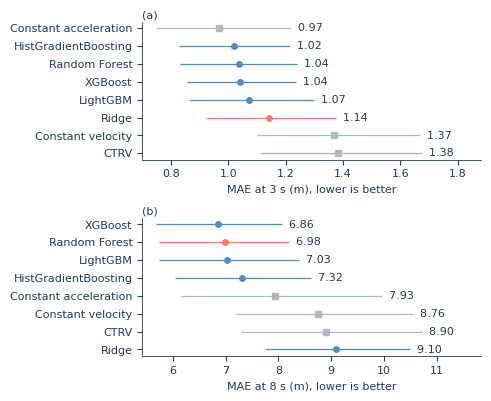

Fig. 3. The selected model reduces MAE relative to constant velocity by 16.7% (95% CI -1.6 to 31.0) at 3 s (Ridge) and by 20.3% (95% CI 8.4 to 30.5) at 8 s (Random Forest); against constant acceleration the change is -18.0% (95% CI -39.3 to -2.7) at 3 s and +11.9% (95% CI -6.2 to +27.5) at 8 s. (a) 3-s and (b) 8-s test MAE of three physical baselines (squares) and five tuned tabular models (circles); the coral marker is the model chosen by train-only grouped cross-validation. Bars are 95% scenario-cluster bootstrap intervals (2,000 resamples) over the same 355 test vehicles from 316 scenarios; the panels use different x-axis ranges.


In [7]:
# Figure: main results as dot plot with 95% CIs, one panel per horizon
fig, axes = plt.subplots(2, 1, figsize=(FIG_W, 3.9))
for ax, h, lab in zip(axes, HORIZONS, ["(a)", "(b)"]):
    r = res[res["horizon"] == h].sort_values("MAE", ascending=False).reset_index(drop=True)
    for yp, row in r.iterrows():
        col = C_ACCENT if row.selected else (C_GREY if row.kind == "physical baseline" else C_MID)
        ax.errorbar(row.MAE, yp, xerr=[[row.MAE - row.MAE_CI_low], [row.MAE_CI_high - row.MAE]],
                    fmt="s" if row.kind == "physical baseline" else "o", color=col, ms=4, elinewidth=0.9, capsize=0)
        ax.text(row.MAE_CI_high, yp, f"  {row.MAE:.2f}", va="center")
    ax.set_yticks(range(len(r)))
    ax.set_yticklabels(r["method"])
    span = r["MAE_CI_high"].max() - r["MAE_CI_low"].min()
    ax.set_xlim(r["MAE_CI_low"].min() - 0.05 * span, r["MAE_CI_high"].max() + 0.22 * span)
    ax.set_xlabel(f"MAE at {h[0]} s (m), lower is better")
    ax.set_title(lab, loc="left", fontsize=8, pad=3)
fig.tight_layout(pad=0.4, h_pad=1.0)
save_fig(fig, "fig_main_results")
def red_ca(h, m):
    r = res[(res["horizon"] == h) & (res["method"] == m)].iloc[0]
    return f"{r.reduction_vs_CA_pct:+.1f}% (95% CI {r.reduction_vs_CA_CI_low:+.1f} to {r.reduction_vs_CA_CI_high:+.1f})"
def red(h, m):
    r = res[(res["horizon"] == h) & (res["method"] == m)].iloc[0]
    return f"{r.reduction_vs_CV_pct:.1f}% (95% CI {r.reduction_CI_low:.1f} to {r.reduction_CI_high:.1f})"
cap = (f"Fig. 3. The selected model reduces MAE relative to constant velocity by {red('3s', SELECTED['3s'])} at 3 s "
       f"({SELECTED['3s']}) and by {red('8s', SELECTED['8s'])} at 8 s ({SELECTED['8s']}); against constant acceleration the change is {red_ca('3s', SELECTED['3s'])} at 3 s and {red_ca('8s', SELECTED['8s'])} at 8 s. "
       f"(a) 3-s and (b) 8-s test MAE of three physical baselines (squares) and five tuned tabular models (circles); "
       f"the coral marker is the model chosen by train-only grouped cross-validation. Bars are 95% scenario-cluster "
       f"bootstrap intervals ({N_BOOT:,} resamples) over the same {nv} test vehicles from {ns} scenarios; the panels use "
       f"different x-axis ranges.")
save_text("fig_main_results_caption.txt", cap)

### Độ ổn định qua 5 cách chia theo cảnh (góp ý 3.2, 5.7)

Lặp phép so mô hình chính với cách "giữ nguyên tốc độ" trên 5 cách chia khác nhau. Tham số đã tinh chỉnh giữ nguyên.

In [8]:
# Robustness over five scenario splits (split seed changes; tuned parameters fixed)
rob = []
for sseed in [SPLIT_SEED, 0, 1, 2, 3]:
    tr_k, te_k = scenario_split(core, seed=sseed)
    for h, sec in HORIZONS.items():
        m = SELECTED[h]
        p = clip0(make_model(m, 0, BEST[(h, m)]).fit(tr_k[X_COLS], tr_k[TARGET[h]]).predict(te_k[X_COLS]))
        y = te_k[TARGET[h]].to_numpy()
        rob.append({"split_seed": sseed, "horizon": h, "model": m, "test_vehicles": len(te_k), "MAE": MAE(y, p),
                    "CV_MAE": MAE(y, te_k["speed"].to_numpy() * sec), "reduction_vs_CV_pct": 100 * (1 - MAE(y, p) / MAE(y, te_k["speed"].to_numpy() * sec))})
rob = pd.DataFrame(rob)
rob.to_csv("report/table_split_robustness.csv", index=False)
rob_sum = rob.groupby("horizon")[["MAE", "CV_MAE", "reduction_vs_CV_pct"]].agg(["mean", "std"]).round(3)
display(rob_sum)

MAE        CV_MAE        reduction_vs_CV_pct       
          mean    std   mean    std                mean    std
horizon                                                       
3s       1.106  0.115  1.351  0.097              18.146  5.525
8s       6.516  0.720  8.317  0.693              21.765  3.765

## Chẩn đoán và giải thích mô hình CORE

- **Sai số theo trạng thái chuyển động** (góp ý 3.3).
- **Chia theo cảnh so với chia ngẫu nhiên theo dòng** (góp ý 3.5).
- **Hình dự đoán và thực tế.**
- **SHAP** qua 5 seed, kèm độ ổn định (góp ý 4.5).

In [9]:
# MAE by motion state at the forecast origin
mrows = []
for h in HORIZONS:
    y = test[TARGET[h]].to_numpy()
    for state in ["stationary", "moving"]:
        m = (test["motion_state"] == state).to_numpy()
        for meth, p in PRED[h].items():
            mrows.append({"horizon": h, "motion_state": state, "n_vehicles": int(m.sum()), "method": meth, "MAE": MAE(y[m], p[m])})
motion = pd.DataFrame(mrows)
motion.to_csv("report/table_motion_state.csv", index=False)
display(motion.pivot_table(index=["horizon", "method"], columns="motion_state", values="MAE").round(3))
print(motion.groupby(["horizon", "motion_state"])["n_vehicles"].first())

motion_state                   moving  stationary
horizon method                                   
3s      CTRV                    3.707       0.163
        Constant acceleration   2.494       0.167
        Constant velocity       3.676       0.163
        HistGradientBoosting    2.611       0.186
        LightGBM                2.698       0.221
        Random Forest           2.692       0.169
        Ridge                   2.679       0.336
        XGBoost                 2.614       0.215
8s      CTRV                   22.020       2.029
        Constant acceleration  19.200       2.023
        Constant velocity      21.601       2.029
        HistGradientBoosting   17.456       2.007
        LightGBM               16.957       1.835
        Random Forest          17.003       1.731
        Ridge                  18.448       4.199
        XGBoost                16.313       1.911

horizon  motion_state
3s       moving          122
         stationary      233
8s       moving          122
         stationary      233
Name: n_vehicles, dtype: int64


In [10]:
# Scenario-disjoint vs random-row split for the selected 3 s model
full = pd.read_parquet("data/processed/feat.parquet").dropna(subset=X_COLS + ["y_disp_3s"])
sel3 = SELECTED["3s"]
sc_rows = []
for label, d in [("all steps (feat.parquet)", full), ("step 10 (one row per vehicle)", core)]:
    tr_s, te_s = scenario_split(d)
    m = np.random.RandomState(SPLIT_SEED).rand(len(d)) < TEST_FRAC
    for split, (a, b) in {"scenario-disjoint": (tr_s, te_s), "random rows": (d[~m], d[m])}.items():
        p = clip0(make_model(sel3, 0, BEST[("3s", sel3)]).fit(a[X_COLS], a["y_disp_3s"]).predict(b[X_COLS]))
        mae, cvm = MAE(b["y_disp_3s"], p), MAE(b["y_disp_3s"], b["speed"] * 3)
        sc_rows.append({"table": label, "split": split, "test_rows": len(b), "test_vehicles": b["unit"].nunique(),
                        "vehicles_in_train_and_test": len(set(a["unit"]) & set(b["unit"])), "MAE": mae, "CV_MAE": cvm,
                        "MAE_over_CV": mae / cvm})
split_cmp = pd.DataFrame(sc_rows)
split_cmp.to_csv("report/table_split_comparison.csv", index=False)
display(split_cmp.round(4))

,table,split,test_rows,test_vehicles,vehicles_in_train_and_test,MAE,CV_MAE,MAE_over_CV
0,all steps (feat.parquet),scenario-disjoint,17817,352,0,1.0531,1.5505,0.6792
1,all steps (feat.parquet),random rows,18139,1197,1197,0.9709,1.3274,0.7314
2,step 10 (one row per vehicle),scenario-disjoint,355,355,0,1.1408,1.3701,0.8326
3,step 10 (one row per vehicle),random rows,369,369,0,1.1109,1.4900,0.7456


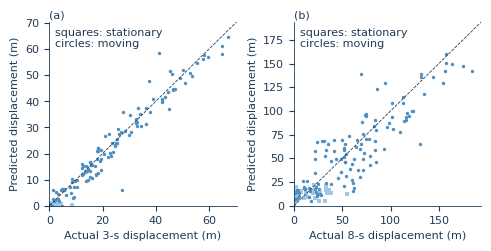

In [11]:
# Predicted vs actual for the selected model at both horizons (paper style: no titles, direct labels)
fig, axes = plt.subplots(1, 2, figsize=(FIG_W, 2.4))
for ax, h, lab in zip(axes, HORIZONS, ["(a)", "(b)"]):
    y, p = test[TARGET[h]].to_numpy(), PRED[h][SELECTED[h]]
    mv = (test["motion_state"] == "moving").to_numpy()
    lim = max(y.max(), p.max()) * 1.05
    ax.scatter(y[~mv], p[~mv], s=6, marker="s", color=C_BASE, linewidths=0)
    ax.scatter(y[mv], p[mv], s=6, color=C_MID, linewidths=0)
    ax.plot([0, lim], [0, lim], color=C_TEXT, lw=0.6, ls="--")
    ax.text(0.03 * lim, 0.97 * lim, "squares: stationary\ncircles: moving", ha="left", va="top")
    ax.set_xlim(0, lim)
    ax.set_ylim(0, lim)
    ax.set_xlabel(f"Actual {h[0]}-s displacement (m)")
    ax.set_ylabel("Predicted displacement (m)")
    ax.set_title(lab, loc="left", fontsize=8, pad=3)
fig.tight_layout(pad=0.4, w_pad=1.0)
save_fig(fig, "fig_pred_actual")

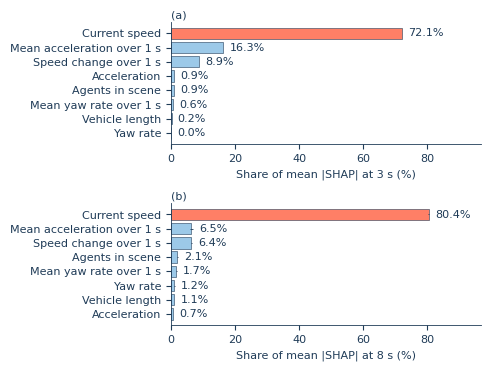

Fig. 4. Current speed carries 72.1% of the mean absolute SHAP value at 3 s (Ridge) and current speed carries 80.4% at 8 s (Random Forest). (a) 3-s and (b) 8-s normalised mean |SHAP| on the 355 test vehicles; bars are the mean over 5 model seeds and whiskers the range across seeds. SHAP values describe model dependence, not causal effects.


In [12]:
# SHAP shares (5 model seeds) for the selected model at each horizon
import shap
def shap_share(model, Xbg, X):
    if isinstance(model, Pipeline):
        sc, lin = model.steps[0][1], model.steps[-1][1]
        sv = shap.LinearExplainer(lin, sc.transform(Xbg)).shap_values(sc.transform(X))
    else:
        try:
            sv = shap.TreeExplainer(model).shap_values(X)
        except Exception:
            sv = shap.Explainer(model.predict, Xbg.sample(min(200, len(Xbg)), random_state=0))(X).values
    v = np.abs(np.asarray(sv)).mean(axis=0)
    return v / v.sum()
srows = []
for h in HORIZONS:
    sel = SELECTED[h]
    for s in ([0] if sel == "Ridge" else MODEL_SEEDS):
        mdl = make_model(sel, s, BEST[(h, sel)]).fit(Xtr, train[TARGET[h]])
        srows += [{"horizon": h, "model": sel, "seed": s, "feature": f, "share": v} for f, v in zip(X_COLS, shap_share(mdl, Xtr, Xte))]
shap_seed = pd.DataFrame(srows)
shap_sum = shap_seed.groupby(["horizon", "model", "feature"])["share"].agg(["mean", "min", "max"]).reset_index()
shap_sum.to_csv("report/table_shap.csv", index=False)
xmax = 100 * shap_sum["max"].max() * 1.2  # one x range for both panels
fig, axes = plt.subplots(2, 1, figsize=(FIG_W, 3.6))
for ax, h, lab in zip(axes, HORIZONS, ["(a)", "(b)"]):
    d = shap_sum[shap_sum["horizon"] == h].sort_values("mean").reset_index(drop=True)
    cols = [C_ACCENT if i == len(d) - 1 else C_BASE for i in range(len(d))]
    ax.barh(range(len(d)), 100 * d["mean"], color=cols, edgecolor=C_TEXT, linewidth=0.4,
            xerr=[np.maximum(0, 100 * (d["mean"] - d["min"])), np.maximum(0, 100 * (d["max"] - d["mean"]))], error_kw={"elinewidth": 0.6, "ecolor": C_TEXT})
    for i, v in enumerate(100 * d["max"]):
        ax.text(v + 0.02 * xmax, i, f"{100 * d['mean'].iloc[i]:.1f}%", va="center")
    ax.set_yticks(range(len(d)))
    ax.set_yticklabels([NICE[f] for f in d["feature"]])
    ax.set_xlim(0, xmax)
    ax.set_xticks(np.arange(0, xmax, 20))
    ax.set_xlabel(f"Share of mean |SHAP| at {h[0]} s (%)")
    ax.set_title(lab, loc="left", fontsize=8, pad=3)
fig.tight_layout(pad=0.4, h_pad=1.0)
save_fig(fig, "fig_shap")
top = {h: shap_sum[shap_sum["horizon"] == h].sort_values("mean").iloc[-1] for h in HORIZONS}
cap = (f"Fig. 4. {NICE[top['3s'].feature]} carries {100 * top['3s']['mean']:.1f}% of the mean absolute SHAP value at 3 s "
       f"({SELECTED['3s']}) and {NICE[top['8s'].feature].lower()} carries {100 * top['8s']['mean']:.1f}% at 8 s ({SELECTED['8s']}). "
       f"(a) 3-s and (b) 8-s normalised mean |SHAP| on the {len(test)} test vehicles; bars are the mean over "
       f"{len(MODEL_SEEDS)} model seeds and whiskers the range across seeds. SHAP values describe model dependence, not causal effects.")
save_text("fig_shap_caption.txt", cap)

In [13]:
# SHAP ranking stability across the five model seeds
shap_seed["rank"] = shap_seed.groupby(["horizon", "seed"])["share"].rank(ascending=False, method="min")
stab = shap_seed.groupby(["horizon", "feature"]).agg(mean_rank=("rank", "mean"), sd_rank=("rank", "std"),
                                                     mean_share=("share", "mean")).reset_index().sort_values(["horizon", "mean_rank"])
stab["feature"] = stab["feature"].map(NICE)
stab.to_csv("report/table_shap_stability.csv", index=False)
display(stab.round(3))

,horizon,feature,mean_rank,sd_rank,mean_share
5,3s,Current speed,1.0,NaN,0.721
1,3s,Mean acceleration over 1 s,2.0,NaN,0.163
2,3s,Speed change over 1 s,3.0,NaN,0.089
0,3s,Acceleration,4.0,NaN,0.009
4,3s,Agents in scene,5.0,NaN,0.009
6,3s,Mean yaw rate over 1 s,6.0,NaN,0.006
3,3s,Vehicle length,7.0,NaN,0.002
7,3s,Yaw rate,8.0,NaN,0.000
13,8s,Current speed,1.0,0.000,0.804
9,8s,Mean acceleration over 1 s,2.2,0.447,0.065


## RQ3: bất định, hiệu quả suy luận và cảnh báo hard cases

- **Khoảng dự báo conformal**, toàn cục và theo trạng thái chuyển động. Bảng ghi tỉ lệ chứa đúng và độ rộng của từng nhóm, độ rộng có cả hai bản: cắt cận dưới tại 0 và chưa cắt (góp ý 3.6, 5.1).
- **Tham số, thời gian chạy và kích thước mô hình** (góp ý 3.8).
- **Bộ cảnh báo**, so với quy tắc tốc độ đơn giản (góp ý 3.7, 5.6).

Phần minh hoạ Chronos đã bỏ theo góp ý (mục 2, dòng 15).

In [14]:
# Scenario and vehicle separation between train and test
print("vehicle overlap:", len(set(train["unit"]) & set(test["unit"])), "| scenario overlap:", len(set(train["scenario"]) & set(test["scenario"])))
assert not set(train["unit"]) & set(test["unit"]) and not set(train["scenario"]) & set(test["scenario"])

vehicle overlap: 0 | scenario overlap: 0


In [15]:
# Split conformal (global and by motion state), coverage and width per group
def q_conf(r):
    n = len(r)
    return np.quantile(r, min(1.0, np.ceil((n + 1) * (1 - ALPHA)) / n), method="higher")
conf_rows = []
for h in HORIZONS:
    sel = SELECTED[h]
    proper, cal = scenario_split(train, seed=SPLIT_SEED + 1, frac=CAL_FRAC)
    mdl = make_model(sel, 0, BEST[(h, sel)]).fit(proper[X_COLS], proper[TARGET[h]])
    r_cal = np.abs(cal[TARGET[h]].to_numpy() - clip0(mdl.predict(cal[X_COLS])))
    cal_state = cal["motion_state"].to_numpy()
    q_all = q_conf(r_cal)
    q_state = {s: (q_conf(r_cal[cal_state == s]) if (cal_state == s).sum() >= 20 else q_all) for s in ["stationary", "moving"]}
    p, y, st = clip0(mdl.predict(Xte)), test[TARGET[h]].to_numpy(), test["motion_state"].to_numpy()
    for method, q in [("global", np.full(len(p), q_all)), ("by motion state", np.array([q_state[s] for s in st]))]:
        lo, hi = np.maximum(0, p - q), p + q
        cov = (y >= lo) & (y <= hi)
        for grp, m in [("all", np.ones(len(p), bool)), ("stationary", st == "stationary"), ("moving", st == "moving")]:
            ci = boot_ci(BOOT_IDX, lambda i: cov[i].mean()) if grp == "all" else (np.nan, np.nan)
            conf_rows.append({"horizon": h, "model": sel, "method": method, "group": grp, "n_test": int(m.sum()),
                              "n_cal": len(cal) if grp == "all" else int((cal_state == grp).sum()), "target": 1 - ALPHA,
                              "coverage": cov[m].mean(), "coverage_CI_low": ci[0], "coverage_CI_high": ci[1],
                              "width_clipped": (hi - lo)[m].mean(), "width_unclipped": (2 * q)[m].mean()})
conf = pd.DataFrame(conf_rows)
conf.to_csv("report/table_conformal.csv", index=False)
display(conf.round(3))

,horizon,model,method,group,n_test,n_cal,target,coverage,coverage_CI_low,coverage_CI_high,width_clipped,width_unclipped
0,3s,Ridge,global,all,355,205,0.9,0.893,0.859,0.924,4.794,7.030
1,3s,Ridge,global,stationary,233,154,0.9,0.987,NaN,NaN,3.759,7.030
2,3s,Ridge,global,moving,122,51,0.9,0.713,NaN,NaN,6.772,7.030
3,3s,Ridge,by motion state,all,355,205,0.9,0.915,0.886,0.942,5.126,5.555
4,3s,Ridge,by motion state,stationary,233,154,0.9,0.893,NaN,NaN,0.664,0.887
5,3s,Ridge,by motion state,moving,122,51,0.9,0.959,NaN,NaN,13.649,14.471
6,8s,Random Forest,global,all,355,205,0.9,0.918,0.889,0.946,33.932,50.336
7,8s,Random Forest,global,stationary,233,154,0.9,0.987,NaN,NaN,26.943,50.336
8,8s,Random Forest,global,moving,122,51,0.9,0.787,NaN,NaN,47.281,50.336
9,8s,Random Forest,by motion state,all,355,205,0.9,0.944,0.919,0.966,40.225,50.439


In [16]:
# Runtime and size of every tuned model
rt = []
X1000 = Xte.sample(1000, replace=True, random_state=0)
for h in HORIZONS:
    for name in MODEL_NAMES:
        m = make_model(name, 0, BEST[(h, name)])
        t0 = time.perf_counter()
        m.fit(Xtr, train[TARGET[h]])
        fit_s = time.perf_counter() - t0
        times = []
        for _ in range(20):
            t0 = time.perf_counter()
            m.predict(X1000)
            times.append(time.perf_counter() - t0)
        single = []
        for _ in range(50):
            t0 = time.perf_counter()
            m.predict(Xte.iloc[[0]])
            single.append(time.perf_counter() - t0)
        t = tune[(tune["horizon"] == h) & (tune["model"] == name)].iloc[0]
        rt.append({"horizon": h, "model": name, "selected": SELECTED[h] == name, "cv_MAE": t.cv_MAE, "tuning_s": t.tuning_s,
                   "fit_s": fit_s, "predict_ms_per_1000": 1000 * np.median(times), "single_row_ms": 1000 * np.median(single), "size_KB": len(pickle.dumps(m)) / 1024,
                   "best_params": t.best_params})
runtime = pd.DataFrame(rt)
runtime.to_csv("report/table_runtime_params.csv", index=False)
display(runtime.drop(columns="best_params").round(3))
print("Hardware:", platform.processor() or platform.machine(), "| CPU cores:", os.cpu_count())

,horizon,model,selected,cv_MAE,tuning_s,fit_s,predict_ms_per_1000,single_row_ms,size_KB
0,3s,Ridge,True,1.033,0.118,0.003,0.600,0.561,1.225
1,3s,Random Forest,False,1.078,37.465,0.330,77.215,46.696,7538.595
2,3s,HistGradientBoosting,False,1.125,17.576,0.245,5.987,1.785,709.171
3,3s,LightGBM,False,1.150,6.427,0.019,1.216,0.480,155.093
4,3s,XGBoost,False,1.037,24.559,0.103,1.183,0.890,325.402
5,8s,Ridge,False,7.766,0.087,0.002,0.550,0.510,1.225
6,8s,Random Forest,True,6.526,36.593,0.210,55.926,36.216,1866.780
7,8s,HistGradientBoosting,False,6.865,16.945,0.243,6.808,1.632,709.718
8,8s,LightGBM,False,6.978,6.469,0.176,12.613,0.634,1881.654
9,8s,XGBoost,False,6.744,24.197,0.090,1.165,0.866,333.695


Hardware: x86_64 | CPU cores: 12


In [17]:
# Hard-error warning: classifier vs speed rules, all metrics at both horizons
warn_rows, WARN = [], {}
for h in HORIZONS:
    sel = SELECTED[h]
    ytr, yte = train[TARGET[h]].to_numpy(), test[TARGET[h]].to_numpy()
    oof = clip0(cross_val_predict(make_model(sel, 0, BEST[(h, sel)]), Xtr, ytr, groups=train["scenario"], cv=GroupKFold(5)))
    thr = np.quantile(np.abs(ytr - oof), 0.90)
    hard_tr, hard_te = (np.abs(ytr - oof) > thr).astype(int), (np.abs(yte - PRED[h][sel]) > thr).astype(int)
    clf = LGBMClassifier(n_estimators=300, learning_rate=0.03, num_leaves=15, class_weight="balanced", random_state=0, verbose=-1)
    p_oof = cross_val_predict(clf, Xtr, hard_tr, groups=train["scenario"], cv=GroupKFold(5), method="predict_proba")[:, 1]
    cand = np.unique(np.quantile(p_oof, np.linspace(0.05, 0.95, 91)))
    t_clf = cand[np.argmax([f1_score(hard_tr, p_oof >= t, zero_division=0) for t in cand])]
    p_te = clf.fit(Xtr, hard_tr).predict_proba(Xte)[:, 1]
    s_tr, s_te = train["speed"].to_numpy(), test["speed"].to_numpy()
    cand_s = np.unique(np.quantile(s_tr, np.linspace(0.05, 0.95, 91)))
    t_spd = cand_s[np.argmax([f1_score(hard_tr, s_tr >= t, zero_division=0) for t in cand_s])]
    WARN[h] = (hard_te, p_te >= t_clf)
    for name, score, flag in [("LightGBM warning classifier", p_te, p_te >= t_clf),
                              (f"Rule: speed >= {STOP_SPEED} m/s", s_te, s_te >= STOP_SPEED),
                              (f"Rule: speed >= {t_spd:.2f} m/s (tuned on train)", s_te, s_te >= t_spd)]:
        two = 0 < hard_te.mean() < 1
        warn_rows.append({"horizon": h, "warner": name, "hard_threshold_m": thr, "hard_rate": hard_te.mean(),
                          "warning_rate": flag.mean(), "ROC_AUC": roc_auc_score(hard_te, score) if two else np.nan,
                          "PR_AUC": average_precision_score(hard_te, score) if two else np.nan,
                          "precision": precision_score(hard_te, flag, zero_division=0),
                          "recall": recall_score(hard_te, flag, zero_division=0), "F1": f1_score(hard_te, flag, zero_division=0)})
warn = pd.DataFrame(warn_rows)
warn.to_csv("report/table_warning.csv", index=False)
display(warn.round(3))

,horizon,warner,hard_threshold_m,hard_rate,warning_rate,ROC_AUC,PR_AUC,precision,recall,F1
0,3s,LightGBM warning classifier,3.123,0.115,0.296,0.885,0.412,0.343,0.878,0.493
1,3s,Rule: speed >= 0.5 m/s,3.123,0.115,0.344,0.862,0.357,0.311,0.927,0.466
2,3s,Rule: speed >= 1.44 m/s (tuned on train),3.123,0.115,0.304,0.862,0.357,0.333,0.878,0.483
3,8s,LightGBM warning classifier,21.104,0.124,0.203,0.900,0.486,0.403,0.659,0.500
4,8s,Rule: speed >= 0.5 m/s,21.104,0.124,0.344,0.884,0.418,0.328,0.909,0.482
5,8s,Rule: speed >= 5.11 m/s (tuned on train),21.104,0.124,0.206,0.884,0.418,0.397,0.659,0.496


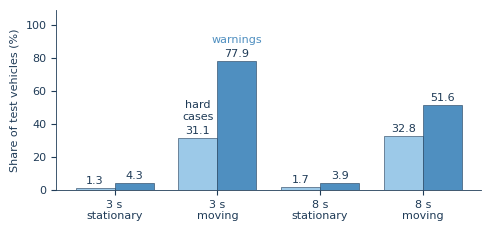

In [18]:
# Figure: hard-case rate vs warning rate of the classifier by motion state (paper style)
grp, hard_r, warn_r = [], [], []
for h in HORIZONS:
    hard_te, flag = WARN[h]
    for s in ["stationary", "moving"]:
        m = (test["motion_state"] == s).to_numpy()
        grp.append(f"{h[0]} s\n{s}"); hard_r.append(100 * hard_te[m].mean()); warn_r.append(100 * flag[m].mean())
x = np.arange(len(grp))
fig, ax = plt.subplots(figsize=(FIG_W, 2.2))
b1 = ax.bar(x - 0.19, hard_r, 0.38, color=C_BASE, edgecolor=C_TEXT, linewidth=0.4)
b2 = ax.bar(x + 0.19, warn_r, 0.38, color=C_MID, edgecolor=C_TEXT, linewidth=0.4)
ax.bar_label(b1, labels=[f"{v:.1f}" for v in hard_r], padding=1.5)
ax.bar_label(b2, labels=[f"{v:.1f}" for v in warn_r], padding=1.5)
k, top = int(np.argmax(warn_r)), max(hard_r + warn_r)
ax.text(x[k] - 0.19, hard_r[k] + 0.13 * top, "hard\ncases", ha="center", va="bottom")
ax.text(x[k] + 0.19, warn_r[k] + 0.13 * top, "warnings", ha="center", va="bottom", color=C_MID)
ax.set_xticks(x)
ax.set_xticklabels(grp)
ax.set_ylim(0, max(hard_r + warn_r) * 1.4)
ax.set_ylabel("Share of test vehicles (%)")
fig.tight_layout(pad=0.4)
save_fig(fig, "fig_warning_by_motion")

## RQ4: ngữ cảnh đèn tín hiệu (WOMD v1.3.0)

So bộ biến cơ bản (8 biến) với bộ cơ bản cộng 4 biến đèn tín hiệu, trên bảng step 10 của mẫu v1.3.0. Thiết kế:

- base và base + traffic dùng cùng dòng;
- chia theo cảnh một lần, dùng chung cho 3 s và 8 s (góp ý 1a, 1b);
- cùng một Random Forest (300 cây, lá tối thiểu 5), dự báo trung bình qua 5 seed;
- phần trăm giảm MAE có khoảng tin cậy 95% bằng bootstrap theo cảnh.

Mẫu v1.3.0 là **một mẫu 1,200 xe khác** với mẫu chính, nên MAE gốc ở đây không so trực tiếp với kết quả chính.

In [19]:
# RQ4: traffic-signal context, single origin, paired comparison with scenario-cluster bootstrap CI
CTX = dict(n_estimators=300, min_samples_leaf=5)
def rf_avg(Xa, ya, Xb):
    return np.mean([clip0(RandomForestRegressor(random_state=s, n_jobs=-1, **CTX).fit(Xa, ya).predict(Xb)) for s in MODEL_SEEDS], axis=0)
def gain_row(exp, variant, h, te, p_base, p_aug, boot):
    y = te[TARGET[h]].to_numpy()
    eb, ea = np.abs(y - p_base), np.abs(y - p_aug)
    lo, hi = boot_ci(boot, lambda i: 100 * (1 - ea[i].mean() / eb[i].mean()))
    by_s = pd.DataFrame({"s": te["scenario"].to_numpy(), "g": eb - ea}).groupby("s")["g"].mean()
    return {"experiment": exp, "variant": variant, "horizon": h,
            "n_test_vehicles": te["unit"].nunique() if "unit" in te.columns else len(te), "n_test_scenarios": te["scenario"].nunique(),
            "base_MAE": eb.mean(), "augmented_MAE": ea.mean(), "base_RMSE": np.sqrt((eb ** 2).mean()),
            "augmented_RMSE": np.sqrt((ea ** 2).mean()), "MAE_reduction_pct": 100 * (1 - ea.mean() / eb.mean()),
            "CI_low": lo, "CI_high": hi, "share_scenarios_improved": (by_s > 0).mean()}
ctx_rows, PCTX = [], {}
# (1) traffic signals, WOMD v1.3.0, single origin
b = pd.read_parquet("data/processed/feat_v1_3_0_origin10.parquet")
t = pd.read_parquet("data/processed/feat_v1_3_0_traffic_origin10.parquet")
assert b[["scenario", "unit", "step"]].equals(t[["scenario", "unit", "step"]])
TL = ["n_traffic_lights", "n_stop_lights", "n_caution_lights", "n_go_lights"]
tr_t, te_t = scenario_split(t)
boot_t = boot_indices(te_t["scenario"])
for h in HORIZONS:
    pb = rf_avg(tr_t[X_COLS], tr_t[TARGET[h]], te_t[X_COLS])
    pa = rf_avg(tr_t[X_COLS + TL], tr_t[TARGET[h]], te_t[X_COLS + TL])
    PCTX[h] = (pb, pa)
    ctx_rows.append(gain_row("Traffic signals (v1.3.0)", "four signal counts", h, te_t, pb, pa, boot_t))
display(pd.DataFrame(ctx_rows).round(4))

,experiment,variant,horizon,n_test_vehicles,n_test_scenarios,base_MAE,augmented_MAE,base_RMSE,augmented_RMSE,MAE_reduction_pct,CI_low,CI_high,share_scenarios_improved
0,Traffic signals (v1.3.0),four signal counts,3s,355,326,1.1201,1.1318,2.8822,2.8951,-1.0451,-2.8872,0.7723,0.3374
1,Traffic signals (v1.3.0),four signal counts,8s,355,326,6.5328,6.4541,12.9838,12.8616,1.2045,-1.2238,3.4260,0.3773


In [20]:
# RQ4 subgroups: scenes with and without traffic lights at the forecast origin
grp_rows = []
for h in HORIZONS:
    y, (pb, pa) = te_t[TARGET[h]].to_numpy(), PCTX[h]
    for g, m in [("traffic lights present", (te_t["n_traffic_lights"] > 0).to_numpy()), ("no traffic lights", (te_t["n_traffic_lights"] == 0).to_numpy())]:
        if m.sum():
            grp_rows.append({"horizon": h, "group": g, "n_vehicles": int(m.sum()), "base_MAE": MAE(y[m], pb[m]),
                             "traffic_MAE": MAE(y[m], pa[m]), "MAE_reduction_pct": 100 * (1 - MAE(y[m], pa[m]) / MAE(y[m], pb[m]))})
rq4_groups = pd.DataFrame(grp_rows)
rq4_groups.to_csv("report/table_rq4_traffic_groups.csv", index=False)
display(rq4_groups.round(4))

,horizon,group,n_vehicles,base_MAE,traffic_MAE,MAE_reduction_pct
0,3s,traffic lights present,222,1.1320,1.1487,-1.4722
1,3s,no traffic lights,133,1.1002,1.1036,-0.3118
2,8s,traffic lights present,222,7.3428,7.2785,0.8752
3,8s,no traffic lights,133,5.1808,5.0781,1.9833


## RQ5: ngữ cảnh lộ trình xe tự lái (WOMD v1.3.1)

- **Dữ liệu:** xe được dự báo là **chính xe tự lái (SDC)**, mỗi cảnh một dòng, đặc trưng lấy tại t = 1.0 s.
- **Phép so:** chỉ biến chuyển động, so với biến chuyển động cộng biến đường đi dự kiến.
- **Kiểm tra rò rỉ (góp ý 5.3):** chạy thêm một bản **bỏ biến `num_on_route_paths`**. Nếu lợi ích ở 8 s gần như biến mất khi bỏ biến này, bài phải ghi rõ.
- **Thiết kế:** mô hình, cách chia và khoảng tin cậy giống RQ4.

In [21]:
# RQ5: SDC route/path context, with and without the on-route count (leakage check)
sdc = pd.read_parquet("data/processed/sdc_v1_3_1_paths.parquet")
MOTION = ["speed", "acc", "yaw_rate", "dspeed_10step", "yaw_ma1s", "length", "n_agents"]
PATH = ["num_valid_paths", "num_on_route_paths", "path_length_mean", "path_length_min", "path_length_max"]
PATH_NR = [c for c in PATH if c != "num_on_route_paths"]
tr_p, te_p = scenario_split(sdc)
boot_p = boot_indices(te_p["scenario"])
for h in HORIZONS:
    pm = rf_avg(tr_p[MOTION], tr_p[TARGET[h]], te_p[MOTION])
    ctx_rows.append(gain_row("SDC route/path (v1.3.1)", "with on-route count", h, te_p, pm,
                             rf_avg(tr_p[MOTION + PATH], tr_p[TARGET[h]], te_p[MOTION + PATH]), boot_p))
    ctx_rows.append(gain_row("SDC route/path (v1.3.1)", "without on-route count", h, te_p, pm,
                             rf_avg(tr_p[MOTION + PATH_NR], tr_p[TARGET[h]], te_p[MOTION + PATH_NR]), boot_p))
ctx = pd.DataFrame(ctx_rows)
ctx.to_csv("report/table_context.csv", index=False)
display(ctx.round(4))

,experiment,variant,horizon,n_test_vehicles,n_test_scenarios,base_MAE,augmented_MAE,base_RMSE,augmented_RMSE,MAE_reduction_pct,CI_low,CI_high,share_scenarios_improved
0,Traffic signals (v1.3.0),four signal counts,3s,355,326,1.1201,1.1318,2.8822,2.8951,-1.0451,-2.8872,0.7723,0.3374
1,Traffic signals (v1.3.0),four signal counts,8s,355,326,6.5328,6.4541,12.9838,12.8616,1.2045,-1.2238,3.4260,0.3773
2,SDC route/path (v1.3.1),with on-route count,3s,2840,2840,1.0137,0.9908,1.5516,1.5319,2.2578,1.2676,3.3183,0.5451
3,SDC route/path (v1.3.1),without on-route count,3s,2840,2840,1.0137,1.0093,1.5516,1.5417,0.4284,-0.4954,1.4124,0.5127
4,SDC route/path (v1.3.1),with on-route count,8s,2840,2840,9.1199,8.4033,12.5542,11.9184,7.8574,6.2625,9.3746,0.5852
5,SDC route/path (v1.3.1),without on-route count,8s,2840,2840,9.1199,8.6815,12.5542,12.1556,4.8070,3.3294,6.3341,0.5616


### Hình ngữ cảnh (gộp Fig. 5 và Fig. 6; góp ý 4.6)

Biểu đồ chấm vẽ trực tiếp phần trăm giảm MAE kèm khoảng tin cậy 95%. Trục ghi "higher is better", có đường 0 làm mốc, và caption ghi rõ giá trị dương nghĩa là sai số thấp hơn.

- Màu san hô: khoảng tin cậy nằm hẳn trên 0, tức chắc chắn có ích.
- Màu xám: khoảng tin cậy nằm hẳn dưới 0, tức làm tệ đi.

Hình tròn là 3 s, hình vuông là 8 s.

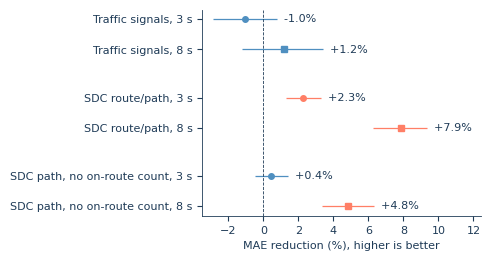

Fig. 5. SDC route/path summaries lower MAE by 7.9% at 8 s (95% CI 6.3 to 9.4) against 2.3% at 3 s, whereas traffic-signal counts change MAE by -1.0% at 3 s and +1.2% at 8 s; without the on-route count the 8-s gain is 4.8%. Positive values mean lower error than the motion-only model. Dots are MAE reductions of a 300-tree random forest (predictions averaged over 5 seeds) with 95% scenario-cluster bootstrap intervals; circles are 3 s, squares 8 s; coral marks intervals above zero and grey intervals below zero. Traffic signals: 355 test vehicles (WOMD v1.3.0); SDC route/path: 2840 test scenarios with the SDC as forecast agent (WOMD v1.3.1).


In [22]:
# Figure: MAE reduction from added context, with 95% CIs
lab = {("Traffic signals (v1.3.0)", "four signal counts"): "Traffic signals",
       ("SDC route/path (v1.3.1)", "with on-route count"): "SDC route/path",
       ("SDC route/path (v1.3.1)", "without on-route count"): "SDC path, no on-route count"}
order = [(e, v, h) for (e, v) in lab for h in HORIZONS]
fig, ax = plt.subplots(figsize=(FIG_W, 2.5))
ypos = []
for k, (e, v, h) in enumerate(order):
    r = ctx[(ctx["experiment"] == e) & (ctx["variant"] == v) & (ctx["horizon"] == h)].iloc[0]
    yp = len(order) - 1 - k - 0.6 * (k // 2)
    ypos.append(yp)
    col = C_ACCENT if r.CI_low > 0 else (C_GREY if r.CI_high < 0 else C_MID)
    ax.errorbar(r.MAE_reduction_pct, yp, xerr=[[r.MAE_reduction_pct - r.CI_low], [r.CI_high - r.MAE_reduction_pct]],
                fmt="o" if h == "3s" else "s", color=col, ms=4, elinewidth=0.9, capsize=0)
    ax.text(max(r.CI_high, 0), yp, f"  {r.MAE_reduction_pct:+.1f}%", va="center")
ax.axvline(0, color=C_TEXT, lw=0.6, ls="--")
ax.set_yticks(ypos)
ax.set_yticklabels([f"{lab[(e, v)]}, {h[0]} s" for e, v, h in order])
lo_, hi_ = ctx["CI_low"].min(), ctx["CI_high"].max()
ax.set_xlim(min(lo_, 0) - 0.05 * (hi_ - lo_), hi_ + 0.25 * (hi_ - lo_))
ax.set_xlabel("MAE reduction (%), higher is better")
fig.tight_layout(pad=0.4)
save_fig(fig, "fig_context")
g = lambda e, v, h: ctx[(ctx["experiment"] == e) & (ctx["variant"] == v) & (ctx["horizon"] == h)].iloc[0]
p3, p8 = g("SDC route/path (v1.3.1)", "with on-route count", "3s"), g("SDC route/path (v1.3.1)", "with on-route count", "8s")
t3, t8 = g("Traffic signals (v1.3.0)", "four signal counts", "3s"), g("Traffic signals (v1.3.0)", "four signal counts", "8s")
n8 = g("SDC route/path (v1.3.1)", "without on-route count", "8s")
cap = (f"Fig. 5. SDC route/path summaries lower MAE by {p8.MAE_reduction_pct:.1f}% at 8 s (95% CI {p8.CI_low:.1f} to {p8.CI_high:.1f}) "
       f"against {p3.MAE_reduction_pct:.1f}% at 3 s, whereas traffic-signal counts change MAE by {t3.MAE_reduction_pct:+.1f}% at 3 s "
       f"and {t8.MAE_reduction_pct:+.1f}% at 8 s; without the on-route count the 8-s gain is {n8.MAE_reduction_pct:.1f}%. "
       f"Positive values mean lower error than the motion-only model. Dots are MAE reductions of a 300-tree random forest "
       f"(predictions averaged over {len(MODEL_SEEDS)} seeds) with 95% scenario-cluster bootstrap intervals; circles are 3 s, squares 8 s; "
       f"coral marks intervals above zero and grey intervals below zero. Traffic signals: {int(t3.n_test_vehicles)} test vehicles "
       f"(WOMD v1.3.0); SDC route/path: {int(p3.n_test_scenarios)} test scenarios with the SDC as forecast agent (WOMD v1.3.1).")
save_text("fig_context_caption.txt", cap)

## Final checks và bảng tổng hợp

Tạo bảng LaTeX tóm tắt RQ4–RQ5, kiểm tra các artifact chính và chạy các assert cuối để bảo đảm không có leakage hay feature target trong đầu vào.
 Sau đó gom số liệu cho bài và tự kiểm các mục của file góp ý.

In [23]:
# Context summary table (LaTeX) for the paper
lines = [r"\begin{table}", r"\centering",
         r"\caption{Change in MAE when context is added to the motion-only random forest at the same forecast origin. "
         r"Positive values mean lower error; brackets are 95\% scenario-cluster bootstrap intervals.}",
         r"\label{tab:context}", r"\begin{tabular}{llrrrr}", r"\toprule",
         r"Context & Horizon & Base MAE (m) & With context (m) & Change (\%) $\uparrow$ & Test scenarios \\", r"\midrule"]
for r in ctx.itertuples():
    lines.append(f"{r.experiment}, {r.variant} & {r.horizon[0]} s & {r.base_MAE:.2f} & {r.augmented_MAE:.2f} & "
                 f"{r.MAE_reduction_pct:+.1f} [{r.CI_low:+.1f}, {r.CI_high:+.1f}] & {r.n_test_scenarios} \\\\")
lines += [r"\bottomrule", r"\end{tabular}", r"\end{table}"]
save_text("table_context.tex", "\n".join(lines))

\begin{table}
\centering
\caption{Change in MAE when context is added to the motion-only random forest at the same forecast origin. Positive values mean lower error; brackets are 95\% scenario-cluster bootstrap intervals.}
\label{tab:context}
\begin{tabular}{llrrrr}
\toprule
Context & Horizon & Base MAE (m) & With context (m) & Change (\%) $\uparrow$ & Test scenarios \\
\midrule
Traffic signals (v1.3.0), four signal counts & 3 s & 1.12 & 1.13 & -1.0 [-2.9, +0.8] & 326 \\
Traffic signals (v1.3.0), four signal counts & 8 s & 6.53 & 6.45 & +1.2 [-1.2, +3.4] & 326 \\
SDC route/path (v1.3.1), with on-route count & 3 s & 1.01 & 0.99 & +2.3 [+1.3, +3.3] & 2840 \\
SDC route/path (v1.3.1), without on-route count & 3 s & 1.01 & 1.01 & +0.4 [-0.5, +1.4] & 2840 \\
SDC route/path (v1.3.1), with on-route count & 8 s & 9.12 & 8.40 & +7.9 [+6.3, +9.4] & 2840 \\
SDC route/path (v1.3.1), without on-route count & 8 s & 9.12 & 8.68 & +4.8 [+3.3, +6.3] & 2840 \\
\bottomrule
\end{tabular}
\end{table}


In [24]:
# Output audit: every file the paper needs from Notebook B
required_b = ["report/table_split.csv", "report/table_tuning.csv", "report/table_main_results.csv", "report/table_main_results.tex",
              "report/fig_main_results.png", "report/fig_main_results.pdf", "report/fig_main_results_caption.txt",
              "report/table_split_robustness.csv", "report/table_motion_state.csv", "report/table_split_comparison.csv",
              "report/fig_pred_actual.png", "report/table_shap.csv", "report/table_shap_stability.csv", "report/fig_shap.png",
              "report/fig_shap.pdf", "report/fig_shap_caption.txt", "report/table_conformal.csv", "report/table_runtime_params.csv",
              "report/table_warning.csv", "report/fig_warning_by_motion.png", "report/table_context.csv",
              "report/table_rq4_traffic_groups.csv", "report/fig_context.png", "report/fig_context.pdf",
              "report/fig_context_caption.txt", "report/table_context.tex"]
missing = [p for p in required_b if not os.path.exists(p)]
print("Missing required:", len(missing), missing)
print("NOTEBOOK B OUTPUT AUDIT: OK" if not missing else "NOTEBOOK B OUTPUT AUDIT: MISSING FILES")

Missing required: 0 []
NOTEBOOK B OUTPUT AUDIT: OK


In [25]:
# Final reproducibility / leakage checks
assert set(train["scenario"]).isdisjoint(set(test["scenario"]))
assert set(tr_t["scenario"]).isdisjoint(set(te_t["scenario"]))
assert set(tr_p["scenario"]).isdisjoint(set(te_p["scenario"]))
assert not any(c.startswith("y_") for c in X_COLS + TL + MOTION + PATH), "target column used as a feature"
assert res.groupby("horizon")["n_test_vehicles"].nunique().eq(1).all(), "3 s and 8 s must use the same test vehicles"
import sys
assert "chronos" not in sys.modules, "Chronos must not be used"
print("ALL NOTEBOOK B CLEAN TESTS: OK")

ALL NOTEBOOK B CLEAN TESTS: OK


In [26]:
# NUMBERS FOR PAPER — Notebook B
P = {}
def put(k, v):
    P[k] = v.item() if hasattr(v, "item") else v
for r in split_tab.itertuples():
    for c in ["rows", "vehicles", "scenarios", "stationary_share"]:
        put(f"split.{r.part}.{c}", getattr(r, c))
for h in HORIZONS:
    put(f"selected.{h}", SELECTED[h])
for r in res.itertuples():
    for c in ["MAE", "MAE_CI_low", "MAE_CI_high", "RMSE", "reduction_vs_CV_pct", "reduction_CI_low", "reduction_CI_high", "reduction_vs_CA_pct", "reduction_vs_CA_CI_low", "reduction_vs_CA_CI_high", "seed_SD"]:
        put(f"main.{r.horizon}.{r.method}.{c}", round(getattr(r, c), 4))
for h in HORIZONS:
    rr = rob[rob["horizon"] == h]
    put(f"robust5splits.{h}.reduction_mean", round(rr["reduction_vs_CV_pct"].mean(), 2))
    put(f"robust5splits.{h}.reduction_sd", round(rr["reduction_vs_CV_pct"].std(), 2))
for r in motion.itertuples():
    put(f"motion.{r.horizon}.{r.motion_state}.{r.method}.MAE", round(r.MAE, 4))
    put(f"motion.{r.horizon}.{r.motion_state}.n_vehicles", r.n_vehicles)
for r in split_cmp.itertuples():
    put(f"splitcmp.{r.table}.{r.split}.MAE_over_CV", round(r.MAE_over_CV, 4))
for r in conf.itertuples():
    for c in ["coverage", "width_clipped", "width_unclipped", "n_test"]:
        put(f"conformal.{r.horizon}.{r.method}.{r.group}.{c}", round(getattr(r, c), 4))
for r in warn.itertuples():
    for c in ["hard_rate", "warning_rate", "ROC_AUC", "PR_AUC", "precision", "recall", "F1"]:
        put(f"warning.{r.horizon}.{r.warner}.{c}", round(getattr(r, c), 4))
for r in runtime.itertuples():
    for c in ["fit_s", "predict_ms_per_1000", "size_KB"]:
        put(f"runtime.{r.horizon}.{r.model}.{c}", round(getattr(r, c), 3))
for r in shap_sum.itertuples():
    put(f"shap.{r.horizon}.{r.feature}.share_pct", round(100 * r.mean, 2))
for r in ctx.itertuples():
    for c in ["base_MAE", "augmented_MAE", "MAE_reduction_pct", "CI_low", "CI_high", "share_scenarios_improved", "n_test_scenarios"]:
        put(f"context.{r.experiment}.{r.variant}.{r.horizon}.{c}", round(getattr(r, c), 4))
numbers = pd.DataFrame({"key": list(P), "value": list(P.values())})
numbers.to_csv("report/paper_numbers_B.csv", index=False)
json.dump(P, open("report/paper_numbers_B.json", "w", encoding="utf-8"), indent=2, default=str)
print(len(numbers), "numbers saved to report/paper_numbers_B.csv")

408 numbers saved to report/paper_numbers_B.csv


## DOCX CHECK: tự kiểm các mục của file góp ý và file hướng dẫn thuộc Notebook B

Bảng in ĐẠT / CHƯA ĐẠT cho từng mục. Dòng "KIỂM TAY" là việc code không kiểm được.

In [27]:
# DOCX CHECK for Notebook B
import sys
R = []
def chk(item, what, fn):
    try:
        ok, detail = fn()
    except Exception as e:
        ok, detail = False, f"error: {type(e).__name__}: {e}"
    R.append({"item": item, "check": what, "result": "ĐẠT" if ok else "CHƯA ĐẠT", "detail": detail})
def manual(item, what):
    R.append({"item": item, "check": what, "result": "KIỂM TAY", "detail": ""})
def width_ok(name):
    w = Image.open(f"report/{name}.png").size[0] / 300
    return abs(w - FIG_W) <= 0.05, f"{w:.2f} in"
chk("1a", "3 s and 8 s use the same test vehicles and the same 8 predictors",
    lambda: (res.groupby("horizon")["n_test_vehicles"].nunique().eq(1).all() and res["n_test_vehicles"].nunique() == 1
             and len(X_COLS) == 8, f"{test['unit'].nunique()} test vehicles"))
chk("1b", "context gains reported separately for traffic signals and SDC route at both horizons",
    lambda: (ctx.groupby("experiment")["horizon"].nunique().eq(2).all(), str(ctx["experiment"].unique().tolist())))
chk("2.15", "Chronos removed", lambda: ("chronos" not in sys.modules, "no chronos import"))
chk("3.1", "main table: every method at both horizons with MAE and RMSE",
    lambda: (res.groupby("horizon")["method"].nunique().eq(len(BASELINES) + len(MODEL_NAMES)).all()
             and os.path.exists("report/table_main_results.tex"), f"{res['method'].nunique()} methods"))
chk("3.2", "95% CI for every MAE", lambda: (res[["MAE_CI_low", "MAE_CI_high"]].notna().all().all(), f"{N_BOOT} scenario-cluster resamples"))
chk("3.3", "MAE split by stationary and moving vehicles", lambda: (set(motion["motion_state"]) == {"stationary", "moving"}, ""))
chk("3.4", "constant-acceleration and CTRV baselines + paired comparison with constant acceleration (CI)",
    lambda: ({"Constant acceleration", "CTRV"} <= set(res["method"]) and res[["reduction_vs_CA_CI_low", "reduction_vs_CA_CI_high"]].notna().all().all(), ""))
chk("3.5", "random-row split run next to scenario split",
    lambda: (set(split_cmp["split"]) == {"scenario-disjoint", "random rows"}, split_cmp[["table", "split", "MAE_over_CV"]].round(3).to_dict("records")))
chk("3.6", "interval coverage and width by speed group", lambda: ({"stationary", "moving"} <= set(conf["group"]), ""))
chk("3.7", "warning table: ROC-AUC, precision, recall, F1 at both horizons",
    lambda: (warn[["ROC_AUC", "precision", "recall", "F1"]].notna().all().all() and warn["horizon"].nunique() == 2, ""))
chk("3.8", "parameters, run time and model size for every model",
    lambda: (len(runtime) == 2 * len(MODEL_NAMES) and runtime[["fit_s", "predict_ms_per_1000", "size_KB"]].notna().all().all(), ""))
chk("4.4", "Fig. 3 replaced by dot plot with CIs + caption at print width",
    lambda: (os.path.exists("report/fig_main_results_caption.txt") and width_ok("fig_main_results")[0], width_ok("fig_main_results")[1]))
chk("4.5", "SHAP figure uses readable feature names, print width",
    lambda: (set(X_COLS) <= set(NICE) and width_ok("fig_shap")[0], width_ok("fig_shap")[1]))
chk("4.6", "context figure caption says positive values mean lower error",
    lambda: ("Positive values mean lower error" in open("report/fig_context_caption.txt", encoding="utf-8").read()
             and width_ok("fig_context")[0], width_ok("fig_context")[1]))
chk("4.7 / guide 2.3", "one style: 8 pt text, white background", lambda: (plt.rcParams["font.size"] >= 8, f"{plt.rcParams['font.size']} pt"))
chk("5.1", "interval width reported clipped and unclipped", lambda: ({"width_clipped", "width_unclipped"} <= set(conf.columns), ""))
chk("5.3", "SDC route ablation without on-route count", lambda: ("without on-route count" in set(ctx["variant"]), ""))
chk("5.5", "vehicles and scenarios reported next to results",
    lambda: ({"n_test_vehicles", "n_test_scenarios"} <= set(res.columns) and "n_test_scenarios" in ctx.columns, ""))
chk("5.6", "warning classifier compared with simple speed rules", lambda: (warn["warner"].str.startswith("Rule").sum() == 4, ""))
chk("5.7", "seed effect stated: seed_SD (model seeds) + 5 different splits",
    lambda: ("seed_SD" in res.columns and rob["split_seed"].nunique() == 5, ""))
chk("Mục cuối", "paper_numbers_B.csv saved", lambda: (os.path.exists("report/paper_numbers_B.csv"), f"{len(numbers)} numbers"))
manual("5.3", "read WOMD v1.3.1 docs on path_samples/on_route; if derived from the driven future, report the no-route variant")
manual("guide 5.6", "open every PNG: no overlapping labels, readable at print size, legible in grayscale")
manual("Chung", "Restart & Run All finished; execution counts increase without gaps or errors")
check = pd.DataFrame(R)
check.to_csv("report/docx_check_B.csv", index=False)
with pd.option_context("display.max_colwidth", 110, "display.width", 220):
    display(check)
print(f"ĐẠT: {(check['result'] == 'ĐẠT').sum()} | CHƯA ĐẠT: {(check['result'] == 'CHƯA ĐẠT').sum()} | KIỂM TAY: {(check['result'] == 'KIỂM TAY').sum()}")

,item,check,result,detail
0,1a,3 s and 8 s use the same test vehicles and the same 8 predictors,ĐẠT,355 test vehicles
1,1b,context gains reported separately for traffic signals and SDC route at both horizons,ĐẠT,"['Traffic signals (v1.3.0)', 'SDC route/path (v1.3.1)']"
2,2.15,Chronos removed,ĐẠT,no chronos import
3,3.1,main table: every method at both horizons with MAE and RMSE,ĐẠT,8 methods
4,3.2,95% CI for every MAE,ĐẠT,2000 scenario-cluster resamples
5,3.3,MAE split by stationary and moving vehicles,ĐẠT,
6,3.4,constant-acceleration and CTRV baselines + paired comparison with constant acceleration (CI),ĐẠT,
7,3.5,random-row split run next to scenario split,ĐẠT,"[{'table': 'all steps (feat.parquet)', 'split': 'scenario-disjoint', 'MAE_over_CV': 0.679}, {'table': 'all..."
8,3.6,interval coverage and width by speed group,ĐẠT,
9,3.7,"warning table: ROC-AUC, precision, recall, F1 at both horizons",ĐẠT,


ĐẠT: 21 | CHƯA ĐẠT: 0 | KIỂM TAY: 3


## Kết luận

Chỉ viết kết luận từ `report/paper_numbers_B.csv` và các bảng ở trên, không gõ số theo trí nhớ. Các câu cần có:

- **Mô hình chính:** họ được chọn ở 3 s và 8 s (`selected.*`), mức giảm MAE so với "giữ nguyên tốc độ", kèm khoảng tin cậy 95% (`main.*`) và độ dao động qua 5 cách chia (`robust5splits.*`).
- **Xe đứng yên và xe đang chạy** (`motion.*`): sai số chung đẹp hơn thực tế đến mức nào.
- **Khoảng dự báo** (`conformal.*`): tỉ lệ chứa đúng so với mục tiêu 90%, toàn cục và theo trạng thái; độ rộng sau khi cắt và chưa cắt.
- **Bộ cảnh báo** (`warning.*`): F1 của bộ phân loại so với quy tắc tốc độ. Nếu quy tắc ngang bằng hoặc tốt hơn thì nói thẳng.
- **Ngữ cảnh** (`context.*`): đèn tín hiệu và lộ trình xe tự lái, nói riêng từng loại ở từng horizon. Nếu lợi ích của lộ trình biến mất khi bỏ `num_on_route_paths`, ghi rõ điều đó.